In [ ]:
import pandas as pd

df = pd.read_excel("Sample data (1).xlsx")

print(df.head())

      Segment  Country    Product Discount Band  Units Sold  \
0  Government  Germany  Carretera           NaN      1513.0   
1  Government  Germany      Paseo           NaN      1006.0   
2  Government   Canada      Paseo           NaN      1725.0   
3  Government  Germany      Paseo           NaN      1513.0   
4  Government  Germany       Velo           NaN      1006.0   

   Manufacturing Price  Sale Price  Gross Sales  Discounts     Sales  \
0                    3         350     529550.0        0.0  529550.0   
1                   10         350     352100.0        0.0  352100.0   
2                   10         350     603750.0        0.0  603750.0   
3                   10         350     529550.0        0.0  529550.0   
4                  120         350     352100.0        0.0  352100.0   

       COGS    Profit       Date  Month Number Month Name  Year  
0  393380.0  136170.0 2014-12-01            12   December  2014  
1  261560.0   90540.0 2014-06-01             6       Jun

In [ ]:

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()


print("\nSummary Statistics:")
print(df.describe())

Dataset Shape: (700, 16)

Column Names:
['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold', 'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts', ' Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name', 'Year']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Segment              700 non-null    object        
 1   Country              700 non-null    object        
 2   Product              700 non-null    object        
 3   Discount Band        647 non-null    object        
 4   Units Sold           700 non-null    float64       
 5   Manufacturing Price  700 non-null    int64         
 6   Sale Price           700 non-null    int64         
 7   Gross Sales          700 non-null    float64       
 8   Discounts            700 non-null    float64       
 9

In [ ]:

print("Missing Values Before Cleaning:")
print(df.isnull().sum())

df = df.drop_duplicates()

for col in df.select_dtypes(include="number").columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].fillna("Unknown")

print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

print("\nCleaned Dataset Shape:", df.shape)

Missing Values Before Cleaning:
Segment                 0
Country                 0
Product                 0
Discount Band          53
Units Sold              0
Manufacturing Price     0
Sale Price              0
Gross Sales             0
Discounts               0
 Sales                  0
COGS                    0
Profit                  0
Date                    0
Month Number            0
Month Name              0
Year                    0
dtype: int64

Missing Values After Cleaning:
Segment                0
Country                0
Product                0
Discount Band          0
Units Sold             0
Manufacturing Price    0
Sale Price             0
Gross Sales            0
Discounts              0
 Sales                 0
COGS                   0
Profit                 0
Date                   0
Month Number           0
Month Name             0
Year                   0
dtype: int64

Cleaned Dataset Shape: (700, 16)


In [ ]:
print(df.columns.tolist())

['Segment', 'Country', 'Product', 'Discount Band', 'Units Sold', 'Manufacturing Price', 'Sale Price', 'Gross Sales', 'Discounts', ' Sales', 'COGS', 'Profit', 'Date', 'Month Number', 'Month Name', 'Year']


In [ ]:

df.columns = df.columns.str.strip()

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_units = df["Units Sold"].sum()
average_sales = df["Sales"].mean()

print("===== SALES PERFORMANCE SUMMARY =====")
print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Profit: {total_profit:,.2f}")
print(f"Total Units Sold: {total_units:,.0f}")
print(f"Average Sales per Row: {average_sales:,.2f}")

===== SALES PERFORMANCE SUMMARY =====
Total Sales: 118,726,350.26
Total Profit: 16,893,702.26
Total Units Sold: 1,125,806
Average Sales per Row: 169,609.07


In [ ]:

sales_by_country = df.groupby("Country")["Sales"].sum().sort_values(ascending=False)

print("===== SALES BY COUNTRY =====")
print(sales_by_country)

sales_by_product = df.groupby("Product")["Sales"].sum().sort_values(ascending=False)

print("\n===== SALES BY PRODUCT =====")
print(sales_by_product)

===== SALES BY COUNTRY =====
Country
United States of America    2.502983e+07
Canada                      2.488765e+07
France                      2.435417e+07
Germany                     2.350534e+07
Mexico                      2.094935e+07
Name: Sales, dtype: float64

===== SALES BY PRODUCT =====
Product
Paseo        3.301114e+07
VTT          2.051192e+07
Velo         1.825006e+07
Amarilla     1.774712e+07
Montana      1.539080e+07
Carretera    1.381531e+07
Name: Sales, dtype: float64


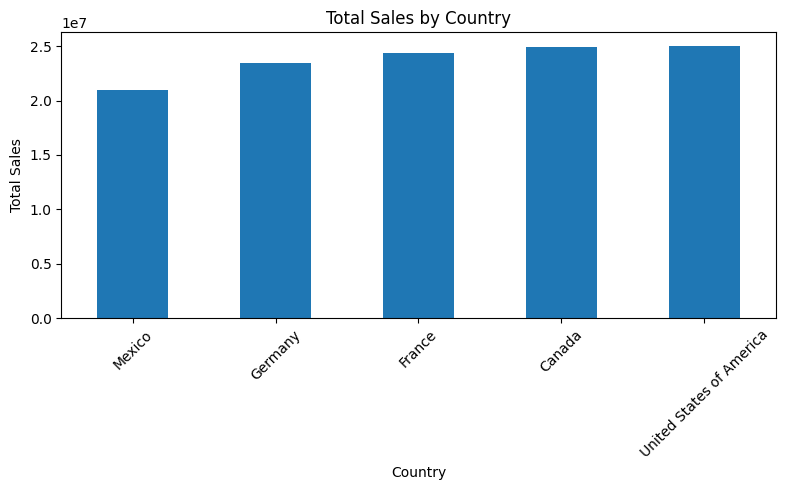

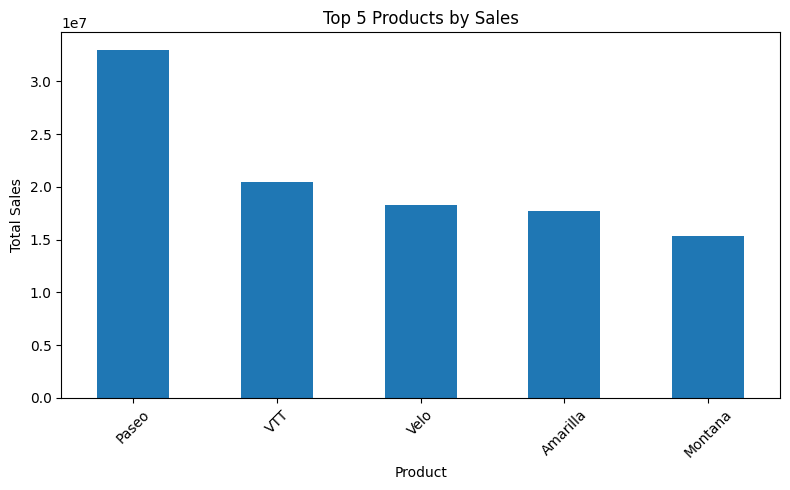

In [ ]:
import matplotlib.pyplot as plt

sales_by_country = df.groupby("Country")["Sales"].sum().sort_values()

sales_by_country.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Country")
plt.xlabel("Country")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

sales_by_product = (
    df.groupby("Product")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

sales_by_product.plot(kind="bar", figsize=(8, 5))
plt.title("Top 5 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:

df.to_csv("cleaned_sales_data.csv", index=False)

print("Cleaned dataset exported successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Cleaned dataset exported successfully!
Rows: 700
Columns: 16


In [10]:
df.to_csv("cleaned_sales_data.csv", index=False)

In [11]:
from google.colab import files
files.download("cleaned_sales_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>